# Практичне заняття № 7 — Хешування, чутливе до розташування (LSH)

**Завдання.** Застосувати LSH до одного з датасетів
[Kaggle: image classification](https://www.kaggle.com/datasets?search=image+classification),
порівняти із результатами класифікації за допомогою будь-якого іншого з раніше
реалізованих алгоритмів.

**Датасет: MNIST** — 10 000 зображень рукописних цифр 28×28 у відтінках сірого,
784 ознаки-пікселі, 10 збалансованих класів.

## Ідея методу

Звичайний пошук найближчих сусідів (практичне заняття № 5) вимагає порівняти
запит з **кожним** об'єктом вибірки. LSH дозволяє цього уникнути: він будує
хеш-функції, для яких **близькі об'єкти з високою ймовірністю потрапляють в один
кошик**, а далекі — в різні. Тоді достатньо переглянути лише вміст кошика запиту.

Це принципова відмінність від звичайного хешування, де мета протилежна — рознести
навіть схожі ключі якнайдалі.

## Реалізація: випадкові гіперплощини (SimHash)

Для косинусної подібності використовують **випадкові гіперплощини**. Кожна
гіперплощина задається випадковим вектором $r$, і біт підпису обчислюється як

$$h_r(x) = \begin{cases} 1, & r \cdot x > 0 \\ 0, & r \cdot x \le 0 \end{cases}$$

Тобто біт каже, з якого боку гіперплощини лежить точка. Ймовірність того, що два
вектори отримають однаковий біт, дорівнює $1 - \theta/\pi$, де $\theta$ — кут між
ними: що менший кут, то вища ймовірність збігу.

$b$ гіперплощин дають $b$-бітний підпис. Об'єкти з однаковим підписом складають
один кошик. Щоб зменшити ризик «розминутися» через невдалий набір гіперплощин,
будують $L$ **незалежних таблиць**, і кандидатами вважають об'єднання кошиків
запиту з усіх таблиць.

У `scikit-learn` LSH відсутній (клас `LSHForest` вилучено), тому алгоритм
реалізовано власноруч.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('mnist.csv', 'wasiqaliyasir/digital-mnist-dataset',
     'mnist.csv', 785, 10000, 'utf-8')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/mnist.csv (18.3 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from collections import defaultdict
from pathlib import Path

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

## 1. Дані

In [3]:
df = pd.read_csv("data/mnist.csv")
y = df["label"].values
X = df.drop(columns=["label"]).values.astype(np.float32)

print(f"Зображень: {X.shape[0]}, ознак: {X.shape[1]} (28×28 пікселів)")
print(f"Класи: {dict(pd.Series(y).value_counts().sort_index())}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print(f"Навчальна: {X_train.shape}, тестова: {X_test.shape}")

Зображень: 10000, ознак: 784 (28×28 пікселів)
Класи: {0: np.int64(980), 1: np.int64(1135), 2: np.int64(1032), 3: np.int64(1010), 4: np.int64(982), 5: np.int64(892), 6: np.int64(958), 7: np.int64(1028), 8: np.int64(974), 9: np.int64(1009)}
Навчальна: (7500, 784), тестова: (2500, 784)


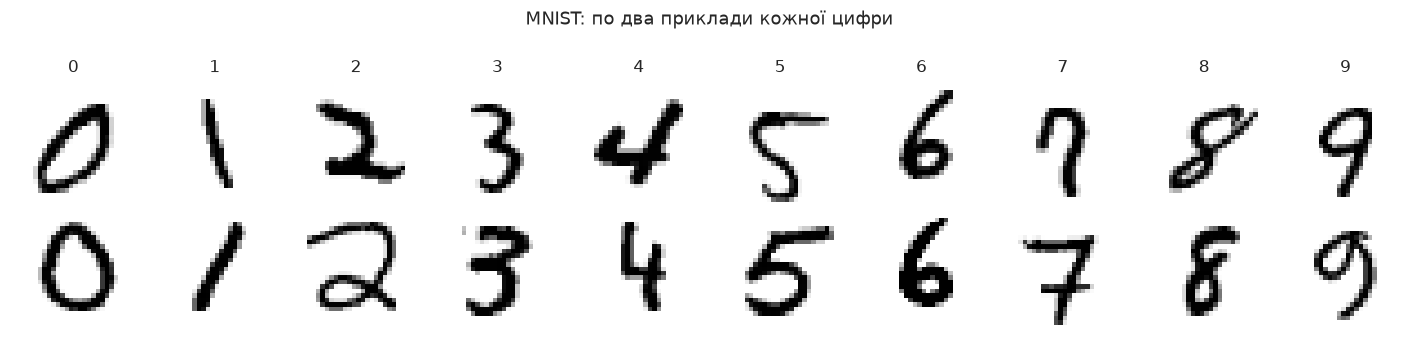

In [4]:
# --- Рисунок 1: приклади зображень ---
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for d in range(10):
    idxs = np.where(y_train == d)[0][:2]
    for r in range(2):
        axes[r, d].imshow(X_train[idxs[r]].reshape(28, 28), cmap="gray_r")
        axes[r, d].axis("off")
        if r == 0:
            axes[r, d].set_title(str(d), fontsize=11)
plt.suptitle("MNIST: по два приклади кожної цифри", y=1.02)
plt.tight_layout()
plt.savefig(ASSETS / "01-samples.png", bbox_inches="tight")
plt.show()

## 2. Реалізація LSH

In [5]:
class RandomProjectionLSH:
    # LSH на випадкових гіперплощинах для косинусної подібності.
    # n_bits  — довжина підпису (скільки гіперплощин на таблицю)
    # n_tables — кількість незалежних таблиць

    def __init__(self, n_bits=16, n_tables=8, random_state=0):
        self.n_bits, self.n_tables = n_bits, n_tables
        self.rng = np.random.RandomState(random_state)

    def _signatures(self, A, table):
        # Знак проєкції на кожну гіперплощину -> біт; біти пакуємо в ціле число
        proj = A @ self.planes[table]              # (n, n_bits)
        bits = (proj > 0).astype(np.uint64)
        weights = (1 << np.arange(self.n_bits, dtype=np.uint64))
        return bits @ weights                      # (n,) ключі кошиків

    def fit(self, X):
        # Нормуємо: для косинусної подібності важливий лише напрямок вектора
        self.norms_ = np.linalg.norm(X, axis=1, keepdims=True)
        self.norms_[self.norms_ == 0] = 1
        self.Xn_ = X / self.norms_
        d = X.shape[1]

        self.planes = [self.rng.randn(d, self.n_bits).astype(np.float32)
                       for _ in range(self.n_tables)]
        self.tables = []
        for t in range(self.n_tables):
            keys = self._signatures(self.Xn_, t)
            buckets = defaultdict(list)
            for i, k in enumerate(keys):
                buckets[k].append(i)
            self.tables.append({k: np.array(v) for k, v in buckets.items()})
        return self

    def candidates(self, q):
        # Об'єднання кошиків запиту з усіх таблиць
        out = set()
        qn = q / (np.linalg.norm(q) or 1)
        for t in range(self.n_tables):
            key = int((((qn @ self.planes[t]) > 0).astype(np.uint64)
                       @ (1 << np.arange(self.n_bits, dtype=np.uint64))))
            hit = self.tables[t].get(key)
            if hit is not None:
                out.update(hit.tolist())
        return np.fromiter(out, dtype=np.int64) if out else np.empty(0, dtype=np.int64)

    def kneighbors(self, q, k=5):
        # Точні відстані рахуємо ЛИШЕ для кандидатів
        cand = self.candidates(q)
        if len(cand) == 0:
            return np.empty(0, dtype=np.int64), 0
        qn = q / (np.linalg.norm(q) or 1)
        sims = self.Xn_[cand] @ qn
        top = cand[np.argsort(-sims)[:k]]
        return top, len(cand)

print("Клас реалізовано.")

Клас реалізовано.


In [6]:
# Перевірка: чи справді LSH знаходить справжніх сусідів?
def exact_neighbors(Xtr, q, k=5):
    Xn = Xtr / np.maximum(np.linalg.norm(Xtr, axis=1, keepdims=True), 1e-12)
    qn = q / (np.linalg.norm(q) or 1)
    return np.argsort(-(Xn @ qn))[:k]

lsh = RandomProjectionLSH(n_bits=16, n_tables=8, random_state=RANDOM_STATE).fit(X_train)
q = X_test[0]
approx, n_cand = lsh.kneighbors(q, k=5)
exact = exact_neighbors(X_train, q, k=5)

print(f"Кандидатів переглянуто: {n_cand} з {len(X_train)} ({n_cand/len(X_train):.1%})")
print(f"Наближені сусіди: {sorted(approx.tolist())}")
print(f"Точні сусіди:     {sorted(exact.tolist())}")
print(f"Збіг: {len(set(approx.tolist()) & set(exact.tolist()))} з 5")

Кандидатів переглянуто: 363 з 7500 (4.8%)
Наближені сусіди: [1125, 2981, 3623, 3950, 5191]
Точні сусіди:     [1125, 2764, 2981, 4261, 5191]
Збіг: 3 з 5


## 3. Головний компроміс: повнота проти швидкості

Параметри $b$ (біт) і $L$ (таблиць) керують компромісом:

- **більше біт** — дрібніші кошики, менше кандидатів, швидше, але вища
  ймовірність втратити справжнього сусіда;
- **більше таблиць** — більше шансів знайти сусіда, але більше кандидатів і
  повільніше.

Вимірюємо **recall@5** — яку частку справжніх п'яти найближчих сусідів LSH
знаходить.

In [7]:
N_EVAL = 300           # запитів для оцінки повноти
eval_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), N_EVAL, replace=False)

# Точні сусіди рахуємо один раз
Xn_train = X_train / np.maximum(np.linalg.norm(X_train, axis=1, keepdims=True), 1e-12)
exact_map = {}
for i in eval_idx:
    qn = X_test[i] / (np.linalg.norm(X_test[i]) or 1)
    exact_map[i] = set(np.argsort(-(Xn_train @ qn))[:5].tolist())

grid_rows = []
for n_bits in [8, 12, 16, 20, 24]:
    for n_tables in [1, 4, 8, 16]:
        L = RandomProjectionLSH(n_bits, n_tables, random_state=RANDOM_STATE).fit(X_train)
        rec, cands = [], []
        t0 = time.time()
        for i in eval_idx:
            approx, nc = L.kneighbors(X_test[i], k=5)
            rec.append(len(set(approx.tolist()) & exact_map[i]) / 5)
            cands.append(nc)
        elapsed = (time.time() - t0) / N_EVAL * 1000
        grid_rows.append({"Біт": n_bits, "Таблиць": n_tables,
                          "Recall@5": np.mean(rec),
                          "Кандидатів, %": np.mean(cands) / len(X_train) * 100,
                          "мс на запит": elapsed})

grid_df = pd.DataFrame(grid_rows)
grid_df.to_csv("data/lsh-grid.csv", index=False)
grid_df.round(4)

,Біт,Таблиць,Recall@5,"Кандидатів, %",мс на запит
0,8,1,0.2107,2.5225,0.2333
1,8,4,0.6313,10.6213,4.6739
2,8,8,0.8540,22.6247,7.5530
3,8,16,0.9547,35.4005,7.0445
4,12,1,0.0980,0.5193,0.0864
5,12,4,0.3547,2.0040,0.2116
6,12,8,0.5587,4.1305,0.9173
7,12,16,0.7700,8.4736,4.2477
8,16,1,0.0860,0.2888,0.0695
9,16,4,0.2407,0.8928,0.2797


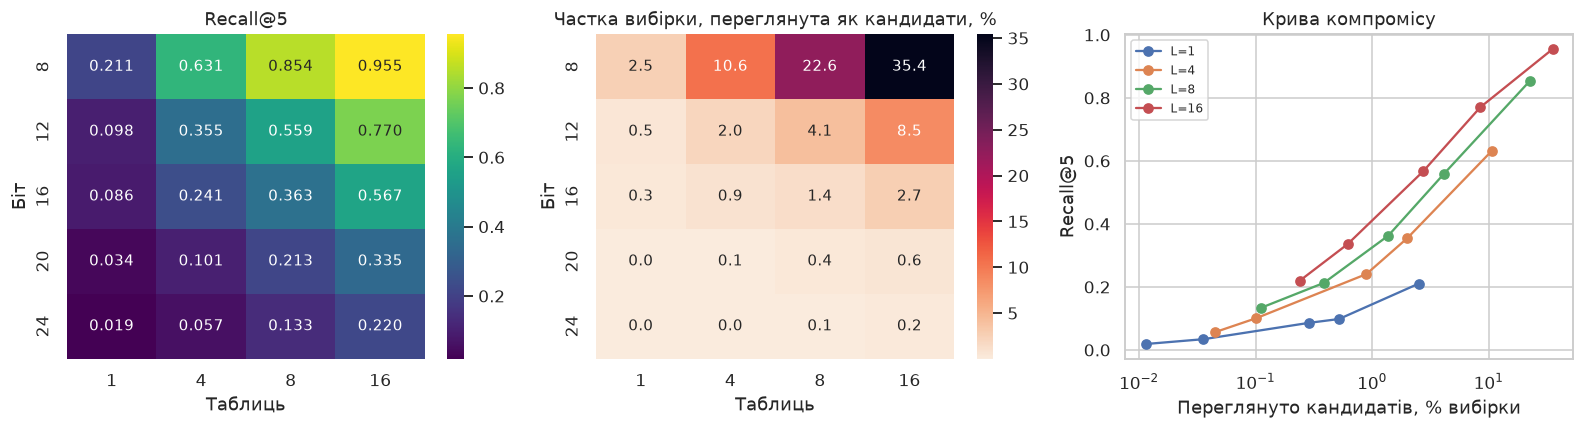

In [8]:
# --- Рисунок 2: компроміс повноти та швидкості ---
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))

piv_r = grid_df.pivot(index="Біт", columns="Таблиць", values="Recall@5")
sns.heatmap(piv_r, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("Recall@5")

piv_c = grid_df.pivot(index="Біт", columns="Таблиць", values="Кандидатів, %")
sns.heatmap(piv_c, annot=True, fmt=".1f", cmap="rocket_r", ax=axes[1])
axes[1].set_title("Частка вибірки, переглянута як кандидати, %")

for nt, grp in grid_df.groupby("Таблиць"):
    axes[2].plot(grp["Кандидатів, %"], grp["Recall@5"], "o-", label=f"L={nt}")
axes[2].set_xlabel("Переглянуто кандидатів, % вибірки")
axes[2].set_ylabel("Recall@5")
axes[2].set_title("Крива компромісу"); axes[2].legend(fontsize=8)
axes[2].set_xscale("log")

plt.tight_layout()
plt.savefig(ASSETS / "02-tradeoff.png", bbox_inches="tight")
plt.show()

## 4. Класифікація на основі LSH

In [9]:
def lsh_classify(lsh, Xtr_labels, queries, k=5):
    preds, cands, found = [], [], 0
    for q in queries:
        nb, nc = lsh.kneighbors(q, k=k)
        cands.append(nc)
        if len(nb) == 0:
            preds.append(-1)              # кошик порожній — відповіді немає
        else:
            found += 1
            vals, cnts = np.unique(Xtr_labels[nb], return_counts=True)
            preds.append(vals[np.argmax(cnts)])
    return np.array(preds), np.mean(cands), found / len(queries)

cls_rows = []
for n_bits, n_tables in [(8, 4), (12, 8), (16, 8), (16, 16), (20, 16), (24, 16)]:
    L = RandomProjectionLSH(n_bits, n_tables, random_state=RANDOM_STATE).fit(X_train)
    t0 = time.time()
    pred, mean_cand, coverage = lsh_classify(L, y_train, X_test, k=5)
    elapsed = (time.time() - t0) / len(X_test) * 1000
    mask = pred >= 0
    cls_rows.append({
        "Біт": n_bits, "Таблиць": n_tables,
        "Точність": accuracy_score(y_test[mask], pred[mask]) if mask.any() else 0,
        "Покриття": coverage,
        "Кандидатів, %": mean_cand / len(X_train) * 100,
        "мс на запит": elapsed,
    })

cls_df = pd.DataFrame(cls_rows)
cls_df.to_csv("data/lsh-classification.csv", index=False)
cls_df.round(4)

,Біт,Таблиць,Точність,Покриття,"Кандидатів, %",мс на запит
0,8,4,0.9324,1.0000,10.7305,4.0309
1,12,8,0.9260,1.0000,4.1551,0.9607
2,16,8,0.8764,0.9996,1.4432,0.2061
3,16,16,0.9188,1.0000,2.8236,0.5870
4,20,16,0.8503,0.9968,0.6354,0.2365
5,24,16,0.7876,0.9624,0.2545,0.2145


«Покриття» — частка запитів, для яких кошик виявився непорожнім. Якщо підпис
надто довгий, кошик запиту може не містити жодного об'єкта, і LSH не дає
відповіді взагалі. Точність рахується лише за тими запитами, де відповідь є.

## 5. Порівняння з точним kNN і раніше реалізованими алгоритмами

In [10]:
baseline_rows = []

# Точний kNN — прямий аналог LSH
for name, model in [("Точний kNN (k=5, косинусна)", KNeighborsClassifier(n_neighbors=5, metric="cosine")),
                    ("Точний kNN (k=5, евклідова)", KNeighborsClassifier(n_neighbors=5))]:
    t0 = time.time(); model.fit(X_train, y_train); fit_t = time.time() - t0
    pts = []
    for _ in range(3):
        t0 = time.time(); pred = model.predict(X_test); pts.append(time.time() - t0)
    pred_t = min(pts) / len(X_test) * 1000
    baseline_rows.append({"Модель": name, "Точність": accuracy_score(y_test, pred),
                          "мс на запит": pred_t, "Навчання, с": fit_t})

# Раніше реалізовані алгоритми
for name, model in [
    ("Логістична регресія (ПЗ № 1)", LogisticRegression(max_iter=1000)),
    ("Дерево рішень (ПЗ № 2)", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ("Випадковий ліс (ПЗ № 2)", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ("SVM RBF (ПЗ № 3)", SVC(kernel="rbf")),
    ("Наївний Баєс (ПЗ № 4)", MultinomialNB()),
]:
    t0 = time.time(); model.fit(X_train, y_train); fit_t = time.time() - t0
    t0 = time.time(); pred = model.predict(X_test); pred_t = (time.time() - t0) / len(X_test) * 1000
    baseline_rows.append({"Модель": name, "Точність": accuracy_score(y_test, pred),
                          "мс на запит": pred_t, "Навчання, с": fit_t})

base_df = pd.DataFrame(baseline_rows).set_index("Модель")
base_df.round(4)

,Точність,мс на запит,"Навчання, с"
Модель,,,
"Точний kNN (k=5, косинусна)",0.9536,0.1222,0.0027
"Точний kNN (k=5, евклідова)",0.9444,0.1143,0.0029
Логістична регресія (ПЗ № 1),0.8816,0.0021,71.0940
Дерево рішень (ПЗ № 2),0.8092,0.0006,1.3256
Випадковий ліс (ПЗ № 2),0.9560,0.0143,0.5416
SVM RBF (ПЗ № 3),0.9604,2.0700,8.4586
Наївний Баєс (ПЗ № 4),0.8356,0.0027,0.1008


In [11]:
# Найкраща конфігурація LSH до спільної таблиці
best = cls_df.loc[cls_df["Точність"].idxmax()]
final = base_df.copy()
final.loc[f"LSH (b={int(best['Біт'])}, L={int(best['Таблиць'])})"] = [
    best["Точність"], best["мс на запит"], np.nan]
final = final.sort_values("Точність", ascending=False)
final.to_csv("data/results-summary.csv")

exact_ms = base_df.loc["Точний kNN (k=5, косинусна)", "мс на запит"]
print(final.round(4).to_string())
print()
print(f"Прискорення LSH відносно точного kNN: {exact_ms / best['мс на запит']:.2f}×")
print(f"Втрата точності: {base_df.loc['Точний kNN (k=5, косинусна)','Точність'] - best['Точність']:+.4f}")
print(f"Переглядається лише {best['Кандидатів, %']:.1f}% вибірки")

                              Точність  мс на запит  Навчання, с
Модель                                                          
SVM RBF (ПЗ № 3)                0.9604       2.0700       8.4586
Випадковий ліс (ПЗ № 2)         0.9560       0.0143       0.5416
Точний kNN (k=5, косинусна)     0.9536       0.1222       0.0027
Точний kNN (k=5, евклідова)     0.9444       0.1143       0.0029
LSH (b=8, L=4)                  0.9324       4.0309          NaN
Логістична регресія (ПЗ № 1)    0.8816       0.0021      71.0940
Наївний Баєс (ПЗ № 4)           0.8356       0.0027       0.1008
Дерево рішень (ПЗ № 2)          0.8092       0.0006       1.3256

Прискорення LSH відносно точного kNN: 0.03×
Втрата точності: +0.0212
Переглядається лише 10.7% вибірки


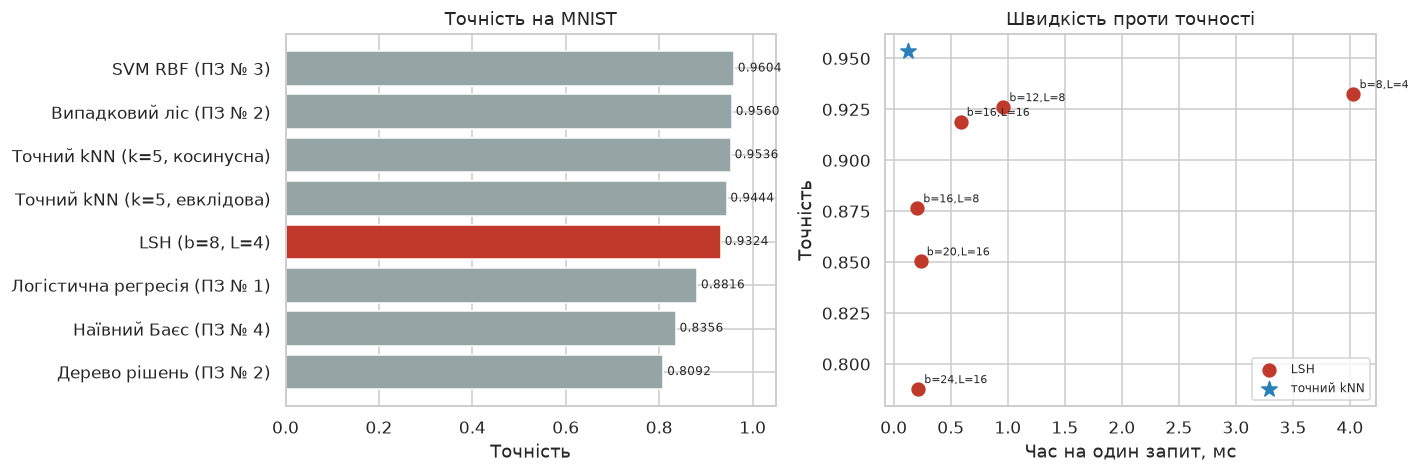

In [12]:
# --- Рисунок 3: точність і швидкість ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

colors = ["#c0392b" if "LSH" in i else "#95a5a6" for i in final.index]
bars = axes[0].barh(final.index[::-1], final["Точність"][::-1], color=colors[::-1])
axes[0].set_xlabel("Точність"); axes[0].set_xlim(0, 1.05)
axes[0].set_title("Точність на MNIST")
for b, v in zip(bars, final["Точність"][::-1]):
    axes[0].text(v + 0.008, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=8)

axes[1].scatter(cls_df["мс на запит"], cls_df["Точність"], s=70, color="#c0392b", label="LSH", zorder=3)
for _, r in cls_df.iterrows():
    axes[1].annotate(f"b={int(r['Біт'])},L={int(r['Таблиць'])}",
                     (r["мс на запит"], r["Точність"]), fontsize=7,
                     xytext=(4, 4), textcoords="offset points")
axes[1].scatter([exact_ms], [base_df.loc["Точний kNN (k=5, косинусна)", "Точність"]],
                s=110, marker="*", color="#2980b9", label="точний kNN", zorder=3)
axes[1].set_xlabel("Час на один запит, мс"); axes[1].set_ylabel("Точність")
axes[1].set_title("Швидкість проти точності"); axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(ASSETS / "03-comparison.png", bbox_inches="tight")
plt.show()

## 6. Чесне порівняння: алгоритм проти реалізації

Попередня таблиця показує, що LSH **повільніший** за точний kNN зі
`scikit-learn`. Це не спростовує метод, а вказує на некоректність прямого
порівняння: `scikit-learn` рахує всю матрицю відстаней однією векторизованою
операцією BLAS на скомпільованому коді, тоді як наша реалізація обходить запити
циклом на Python з операціями над множинами.

Щоб відокремити **алгоритмічний** виграш від якості реалізації, порівняємо LSH з
повним перебором, написаним у тому самому стилі — запит за запитом.

In [13]:
def brute_force_loop(Xtr, Xtr_labels, queries, k=5):
    # Той самий стиль, що й у LSH: цикл по запитах, але переглядаємо ВСЮ вибірку
    Xn = Xtr / np.maximum(np.linalg.norm(Xtr, axis=1, keepdims=True), 1e-12)
    preds = []
    for q in queries:
        qn = q / (np.linalg.norm(q) or 1)
        sims = Xn @ qn
        nb = np.argsort(-sims)[:k]
        vals, cnts = np.unique(Xtr_labels[nb], return_counts=True)
        preds.append(vals[np.argmax(cnts)])
    return np.array(preds)

SUB = 1000
qs = X_test[:SUB]

# Час вимірюємо як МІНІМУМ із трьох повторів: шум завантаження машини лише
# додає час, тому мінімум — найстійкіша оцінка (стандартна практика бенчмаркінгу).
L_best = RandomProjectionLSH(int(best["Біт"]), int(best["Таблиць"]),
                             random_state=RANDOM_STATE).fit(X_train)

def best_of(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.time(); out = fn(); times.append(time.time() - t0)
    return out, min(times) / SUB * 1000

pred_bf, t_bf = best_of(lambda: brute_force_loop(X_train, y_train, qs))
(pred_lsh, mc, cov), t_lsh = best_of(lambda: lsh_classify(L_best, y_train, qs, k=5))

print("Однаковий стиль реалізації (цикл на Python):")
print(f"  Повний перебір: {t_bf:.3f} мс/запит, точність {accuracy_score(y_test[:SUB], pred_bf):.4f}")
print(f"  LSH:            {t_lsh:.3f} мс/запит, точність "
      f"{accuracy_score(y_test[:SUB][pred_lsh>=0], pred_lsh[pred_lsh>=0]):.4f}")
print(f"  Прискорення:    {t_bf/t_lsh:.2f}×")
print()
print(f"Алгоритмічна економія: переглядається {mc/len(X_train)*100:.1f}% вибірки")
print(f"замість 100 %, тобто у {100/(mc/len(X_train)*100):.1f}× менше обчислень відстані.")
print()
print(f"Для довідки, векторизований scikit-learn: {exact_ms:.3f} мс/запит —")
print("він виграє за рахунок реалізації, а не за рахунок алгоритму.")

Однаковий стиль реалізації (цикл на Python):
  Повний перебір: 4.295 мс/запит, точність 0.9590
  LSH:            2.449 мс/запит, точність 0.9420
  Прискорення:    1.75×

Алгоритмічна економія: переглядається 10.6% вибірки
замість 100 %, тобто у 9.4× менше обчислень відстані.

Для довідки, векторизований scikit-learn: 0.122 мс/запит —
він виграє за рахунок реалізації, а не за рахунок алгоритму.


## 7. Підсумок

In [14]:
print("Сітка параметрів LSH:"); print(grid_df.round(4).to_markdown(index=False)); print()
print("Класифікація LSH:");     print(cls_df.round(4).to_markdown(index=False)); print()
print("Порівняння методів:");   print(final.round(4).to_markdown())

Сітка параметрів LSH:
|   Біт |   Таблиць |   Recall@5 |   Кандидатів, % |   мс на запит |
|------:|----------:|-----------:|----------------:|--------------:|
|     8 |         1 |     0.2107 |          2.5225 |        0.2333 |
|     8 |         4 |     0.6313 |         10.6213 |        4.6739 |
|     8 |         8 |     0.854  |         22.6247 |        7.553  |
|     8 |        16 |     0.9547 |         35.4005 |        7.0445 |
|    12 |         1 |     0.098  |          0.5193 |        0.0864 |
|    12 |         4 |     0.3547 |          2.004  |        0.2116 |
|    12 |         8 |     0.5587 |          4.1305 |        0.9173 |
|    12 |        16 |     0.77   |          8.4736 |        4.2477 |
|    16 |         1 |     0.086  |          0.2888 |        0.0695 |
|    16 |         4 |     0.2407 |          0.8928 |        0.2797 |
|    16 |         8 |     0.3627 |          1.3768 |        0.2585 |
|    16 |        16 |     0.5667 |          2.7408 |        0.6086 |
|    20 |   